In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from optuna.samplers import TPESampler
import pandas as pd
import numpy as np
import optuna
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from train import train_val, test, preparing_data

c:\Users\Roman\Education\Project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_stocks = pd.read_csv("data_stocks.csv", sep=";")

Create and train-val model

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hiden_size, num_layers, dropout=0.2):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hiden_size, num_layers=num_layers, dropout=dropout)
        self.linear = nn.Linear(hiden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        # [L, N, D * hiden_size]
        out = out[:, -1, :]
        out = self.linear(out)

        return out

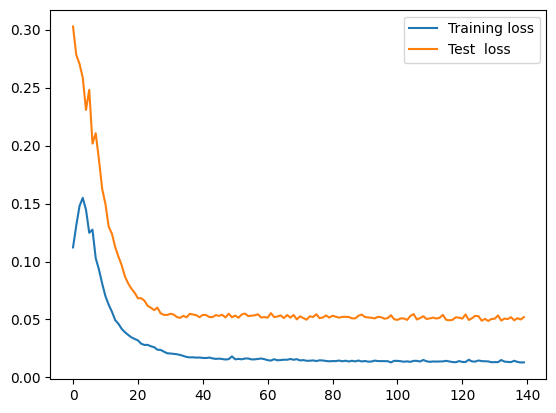

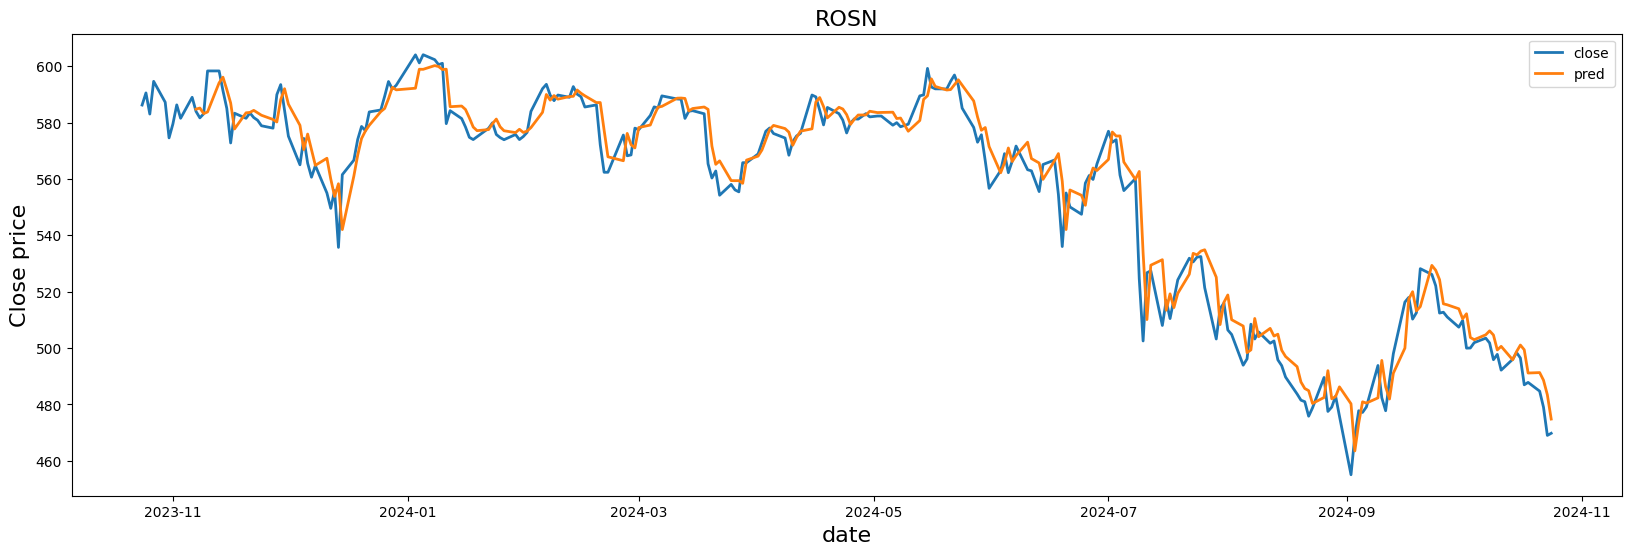

LSTM ROSN RMSE: 8.157869202150868
LSTM ROSN MAE: 5.82375714273949
LSTM ROSN MAPE: 0.010808504819088151


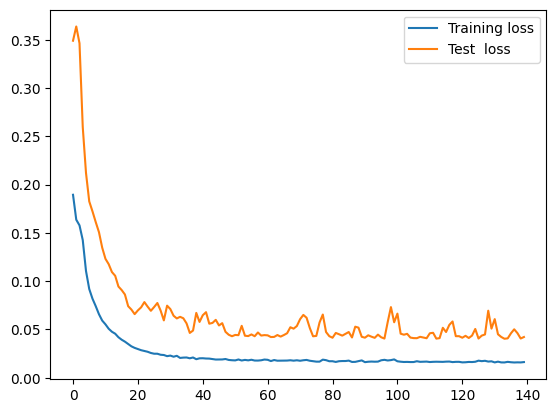

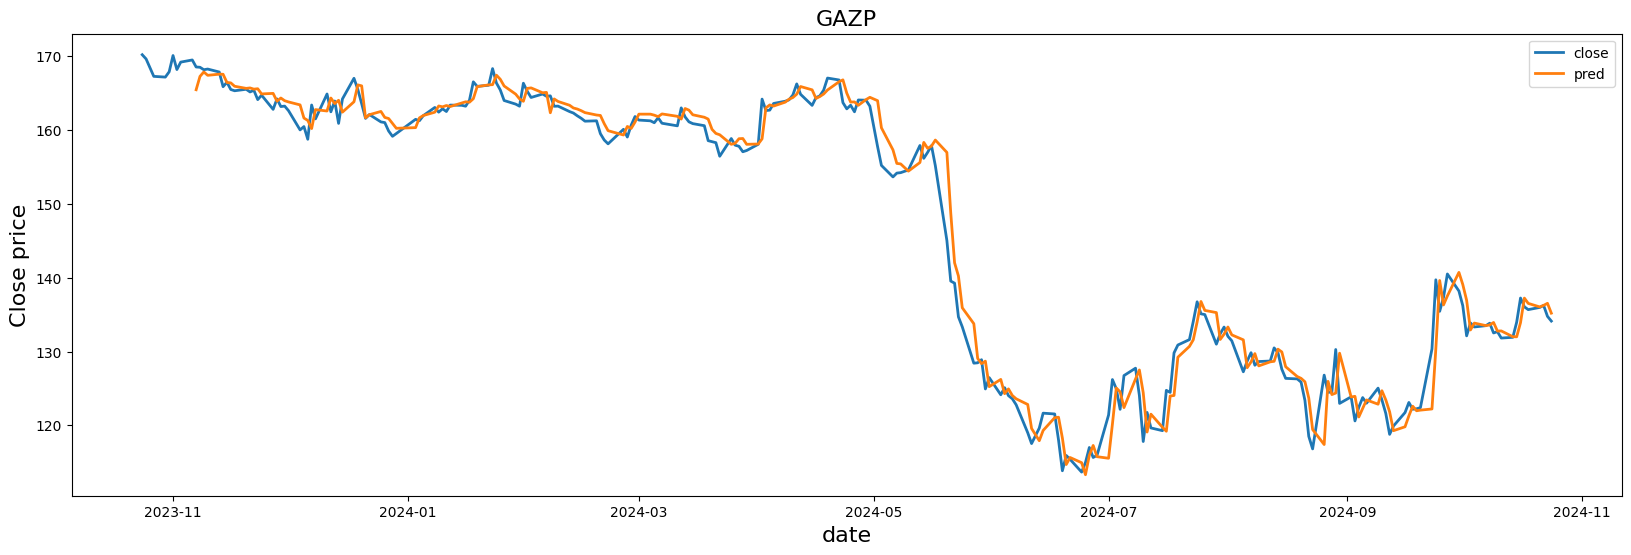

LSTM GAZP RMSE: 2.516676881942264
LSTM GAZP MAE: 1.7253124410046754
LSTM GAZP MAPE: 0.012391383740914808


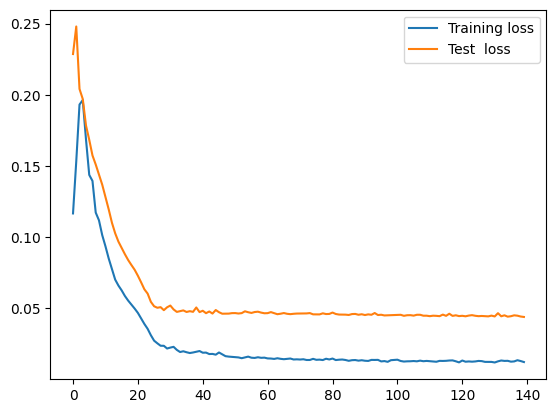

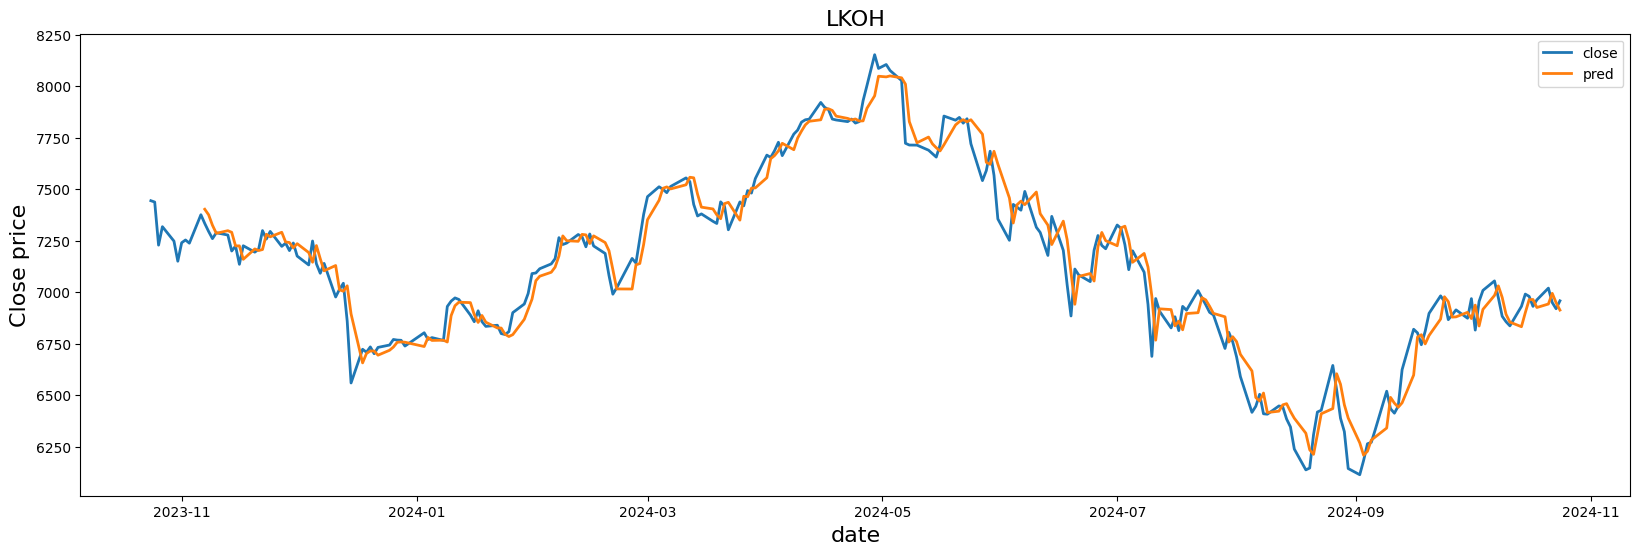

LSTM LKOH RMSE: 92.65317469260403
LSTM LKOH MAE: 69.28420812414906
LSTM LKOH MAPE: 0.00985062982934278


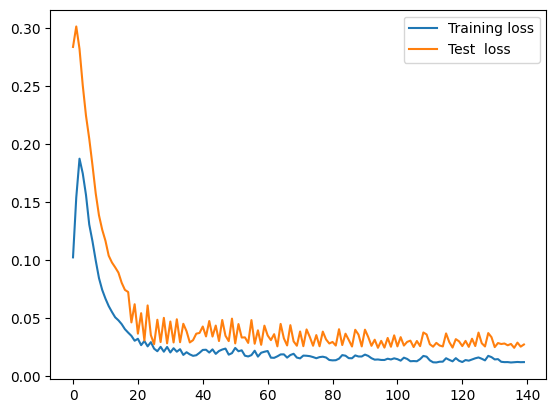

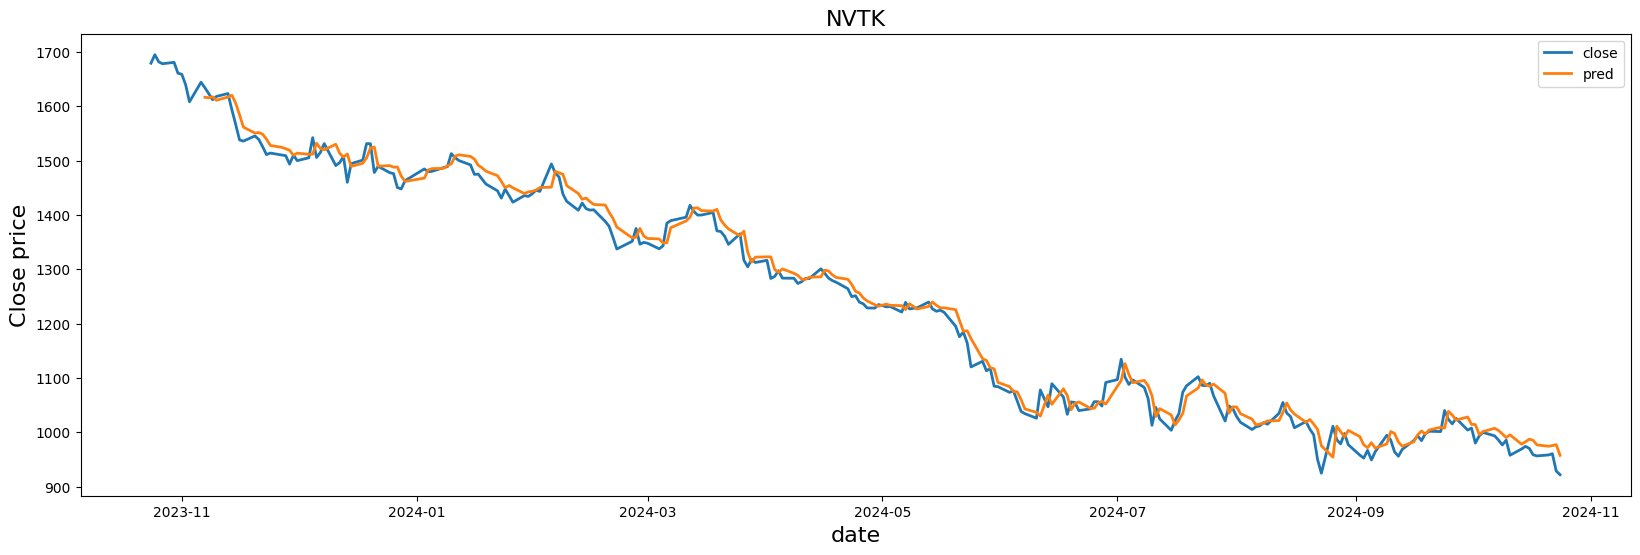

LSTM NVTK RMSE: 21.395380986085645
LSTM NVTK MAE: 16.899374093619073
LSTM NVTK MAPE: 0.014255339357094082


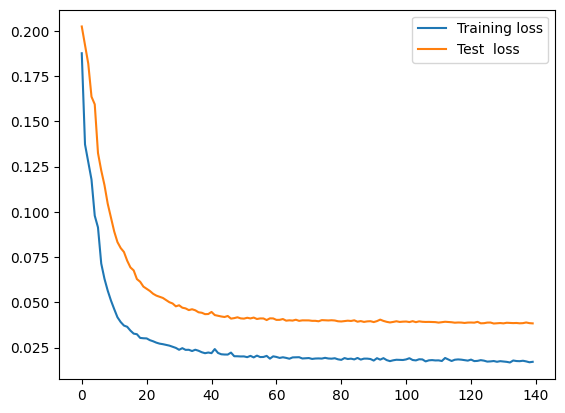

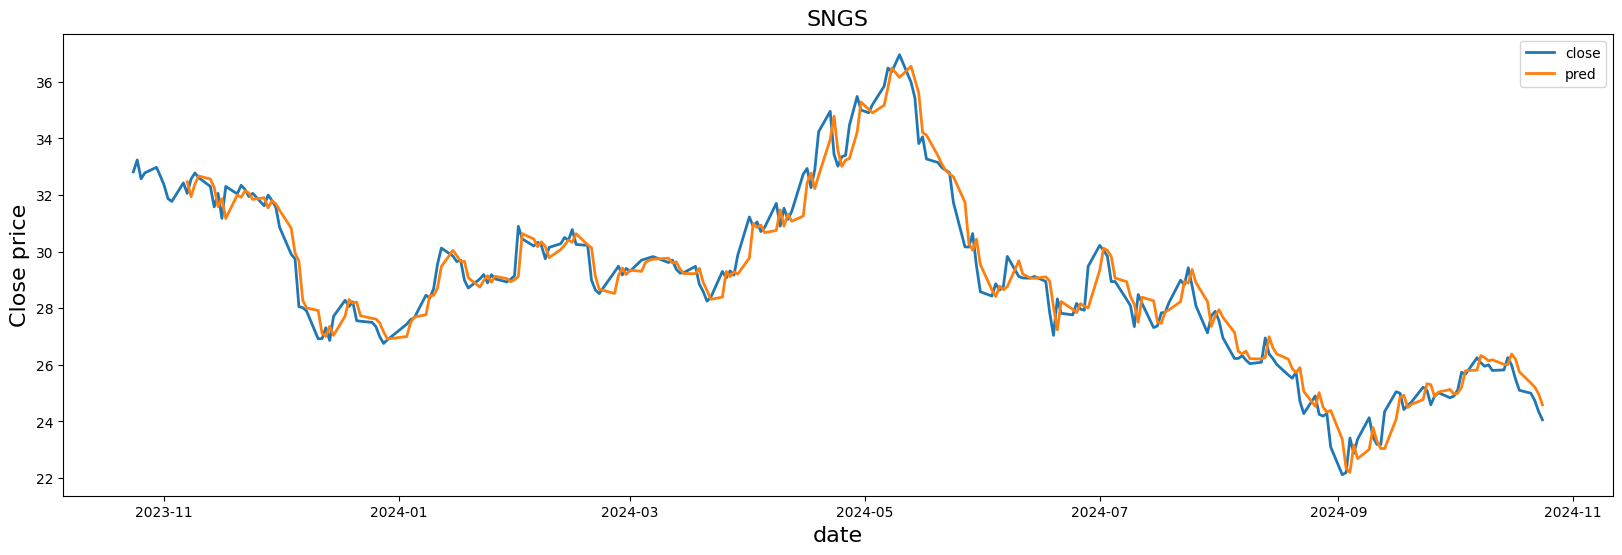

LSTM SNGS RMSE: 0.5900974061981787
LSTM SNGS MAE: 0.44763233896405213
LSTM SNGS MAPE: 0.01561326511055484


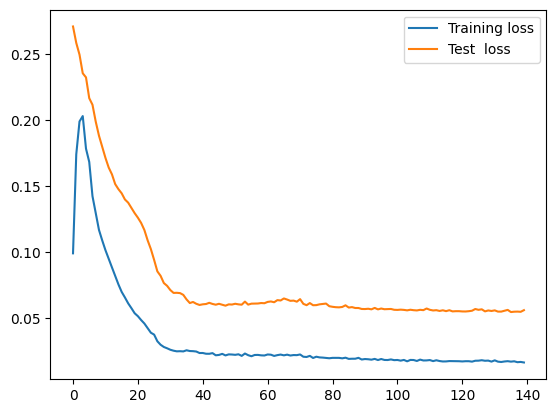

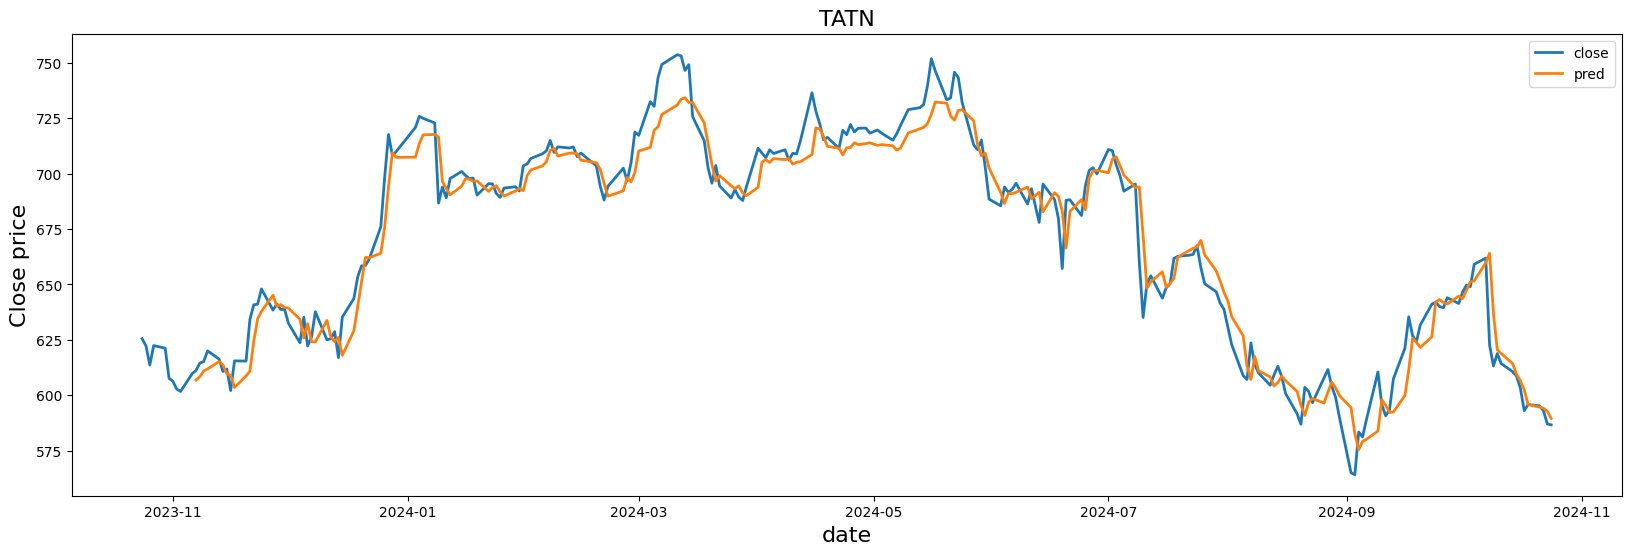

LSTM TATN RMSE: 10.674026945050601
LSTM TATN MAE: 7.860987606198194
LSTM TATN MAPE: 0.01176353104564299


In [6]:
tickers = ['ROSN', 'GAZP', 'LKOH', 'NVTK', 'SNGS', 'TATN']

for ticker in tickers:
    look_back = 10
    hiden_size = 128
    input_size = 1
    num_layers = 3

    model = LSTMModel(input_size=input_size, hiden_size=hiden_size, num_layers=num_layers).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1.3e-4)
    loss_fn = nn.MSELoss()

    ticker_data = data_stocks[data_stocks.company == ticker]
    train_dataloader, test_dataloader, scaler = preparing_data(ticker=ticker_data, look_back=look_back, batch_size=32)

    train_val(model=model, loss_fn=loss_fn, optimizer=optimizer, num_epoch=140, device=device, train_dataloader=train_dataloader, test_dataloader=test_dataloader)
    rmse, mae, mape = test(model=model, device=device, test_dataloader=test_dataloader, ticker=ticker_data, scaler=scaler, look_back=look_back)


Попробуем подобрать оптимальный временной интервал при помощи optuna и Tree-structured Parzen Estimator

In [8]:
rosn = data_stocks[data_stocks.company == "ROSN"]

In [9]:
def objective(trial):
    look_back = trial.suggest_int('lag', 5, 50)
    train_dataloader, test_dataloader, scaler = preparing_data(ticker=rosn, look_back=look_back, batch_size=32)
    
    hiden_size = 128
    input_size = 1
    num_layers = 3

    model = LSTMModel(input_size=input_size, hiden_size=hiden_size, num_layers=num_layers).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1.3e-4)
    loss_fn = nn.MSELoss()

    train_val(model=model, loss_fn=loss_fn, optimizer=optimizer, num_epoch=140, device=device, train_dataloader=train_dataloader, test_dataloader=test_dataloader, plot_=False)
    rmse, mae, mape = test(model=model, device=device, test_dataloader=test_dataloader, ticker=rosn, scaler=scaler, look_back=look_back, plot_=False)

    return rmse

In [10]:
sampler = TPESampler(seed=42)
study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(objective, n_trials=10)

print("Лучшие параметры:", study.best_params)
print("Лучший RMSE:", study.best_value)

[I 2025-05-19 22:05:13,251] A new study created in memory with name: no-name-a9ba0572-72b8-43a4-938a-9af640c7a03b
[I 2025-05-19 22:05:50,213] Trial 0 finished with value: 7.971164140335285 and parameters: {'lag': 22}. Best is trial 0 with value: 7.971164140335285.
[I 2025-05-19 22:06:26,512] Trial 1 finished with value: 8.23832146015526 and parameters: {'lag': 48}. Best is trial 0 with value: 7.971164140335285.
[I 2025-05-19 22:07:02,893] Trial 2 finished with value: 7.98219444124464 and parameters: {'lag': 38}. Best is trial 0 with value: 7.971164140335285.
[I 2025-05-19 22:07:40,116] Trial 3 finished with value: 8.129572541797046 and parameters: {'lag': 32}. Best is trial 0 with value: 7.971164140335285.
[I 2025-05-19 22:08:17,606] Trial 4 finished with value: 7.851080669163493 and parameters: {'lag': 12}. Best is trial 4 with value: 7.851080669163493.
[I 2025-05-19 22:08:54,228] Trial 5 finished with value: 8.401270606236558 and parameters: {'lag': 12}. Best is trial 4 with value: 7

Лучшие параметры: {'lag': 12}
Лучший RMSE: 7.851080669163493
